# 3. Two-stage recommender: candidates then ranker
Stage 1 proposes a few hundred articles per customer from several cheap sources; stage 2 (LightGBM
LambdaRank) orders them. Candidate **recall** is the ceiling for the whole system: the ranker cannot
recommend what stage 1 never proposed.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from hmrec import workspace
pd.set_option("display.width", 140); plt.rcParams["figure.dpi"] = 110

# 10% of customers, seeded. Falls back to a tiny synthetic fixture (with a warning) if the
# real data has not been downloaded yet.
W = workspace.setup(sample_frac=0.10, seed=0)
hm, split = W.hm, W.split
if W.synthetic:
    print("*** SYNTHETIC DATA - numbers below are not H&M results ***")

In [2]:
from hmrec import models as Mo, candidates as C, ranker as R
def sources(ctx):
    return {
        "repurchase": C.Source(Mo.Repurchase(28).fit(ctx), 40),
        "popularity": C.Source(Mo.Popularity(7).fit(ctx), 30),
        "age_pop":    C.Source(Mo.AgePopularity(14).fit(ctx), 30),
        "co_purchase": C.Source(Mo.CoPurchase(days=56).fit(ctx), 50),
        "als":        C.Source(Mo.ALS(factors=64, days=26 * 7).fit(ctx), 50),
    }
pool_val = C.generate(sources(W.ctx_train), W.ev_val.users, W.ev_val.rel)   # labels: validation week
pool_test = C.generate(sources(W.ctx_fit), W.ev_test.users, W.ev_test.rel)  # scored on: test week
print(f"avg candidates per customer: {pool_test.avg_candidates:.0f}")
pd.Series(pool_test.recall, name="candidate recall (test)").sort_values(ascending=False).round(4).to_frame()

avg candidates per customer: 134


,candidate recall (test)
union,0.1456
popularity,0.0500
repurchase,0.0498
age_pop,0.0487
als,0.0474
co_purchase,0.0343


## Features
Built only from purchases before the week being predicted (a unit test fails if that is violated).

In [3]:
fb_val = R.FeatureBuilder(hm, W.ctx_train, W.emb); fb_test = R.FeatureBuilder(hm, W.ctx_fit, W.emb)
frame_val = fb_val.featurize(pool_val.frame); frame_test = fb_test.featurize(pool_test.frame)
feats = [c for c in frame_val.columns if c not in ("user", "item", "label")]
groups = R.feature_groups(feats)
{g: len(v) for g, v in groups.items()}

{'source': 10, 'customer': 14, 'item': 10, 'pair': 7, 'text': 1}

## Train, evaluate, and ablate feature groups

In [4]:
def fit_eval(name, cols):
    rk = R.train_ranker(frame_val, cols, seed=0)
    ranked, scores = R.rank_pool(rk, frame_test, W.ev_test.users)
    return rk, ranked, scores, W.ev_test.metrics_from_ranking(ranked, name)
runs = {"full": fit_eval("full", feats)}
for g in R.GROUPS:
    runs[f"without {g}"] = fit_eval(g, [c for c in feats if c not in groups[g]])
runs["source scores only"] = fit_eval("src", groups["source"])
abl = pd.DataFrame({k: v[3].summary for k, v in runs.items()}).T[["map@12", "recall@12", "ndcg@12"]]
abl["delta vs full"] = abl["map@12"] - abl.loc["full", "map@12"]
abl.round(4)

,map@12,recall@12,ndcg@12,delta vs full
full,0.0307,0.0640,0.0448,0.0000
without source,0.0320,0.0642,0.0461,0.0012
without customer,0.0323,0.0659,0.0469,0.0016
without item,0.0306,0.0658,0.0457,-0.0002
without pair,0.0310,0.0638,0.0450,0.0003
without text,0.0314,0.0630,0.0454,0.0006
source scores only,0.0308,0.0638,0.0448,0.0000


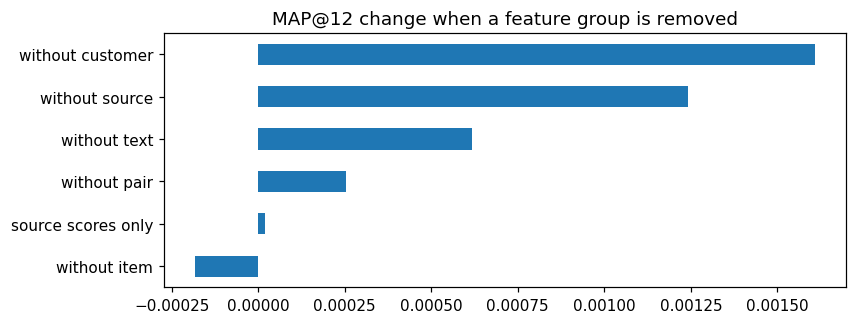

In [5]:
abl["delta vs full"].drop("full").sort_values().plot(kind="barh", figsize=(8, 3), title="MAP@12 change when a feature group is removed"); plt.show()

Differences between runs are small next to the sampling noise of a few thousand customers, so
test each against the full model with a **paired bootstrap** (an interval containing 0 is not evidence
of anything):

In [6]:
from hmrec.evaluate import paired_bootstrap
full = runs["full"][3].per_user["map@12"]
pd.DataFrame({k: paired_bootstrap(full, v[3].per_user["map@12"]) for k, v in runs.items() if k != "full"}).T.round(5)

,diff,lo,hi,significant
without source,-0.001243,-0.003159,0.000523,False
without customer,-0.001609,-0.003344,0.000102,False
without item,0.000182,-0.00169,0.002195,False
without pair,-0.000252,-0.002009,0.001472,False
without text,-0.000617,-0.002193,0.000937,False
source scores only,-0.00002,-0.002079,0.001849,False


## What the model uses

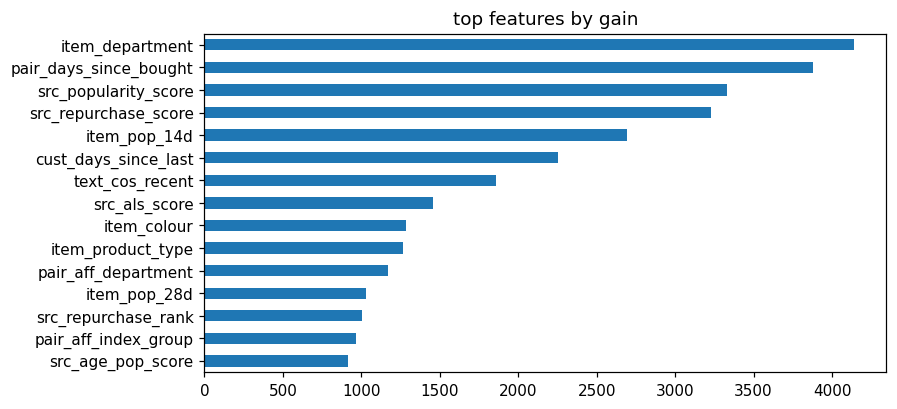

In [7]:
rk = runs["full"][0]
imp = pd.Series(rk.booster.feature_importance("gain"), index=rk.features).sort_values()
imp.tail(15).plot(kind="barh", figsize=(8, 4), title="top features by gain"); plt.show()

**Reading:** compare the full ranker to the best baseline from notebook 2 using a paired bootstrap
before claiming an improvement - with a few thousand evaluation customers, small gaps can be noise.